# Etapa 4: Modelo final, submissão e explicabilidade

**Trabalho em Competição: Detecção de Intrusão em Redes** · Inteligência Artificial · Profa. Cristiane Neri Nobre

Este notebook é a versão **final e reprodutível** do trabalho. Do começo ao fim, ele:

1. carrega e limpa os dados com o `limpar()` de `limpeza.py` (Etapa 1);
2. monta o pipeline final escolhido nas Etapas 2 e 3;
3. refaz a validação cruzada 5×2 do grupo, com métricas por classe e matriz de confusão;
4. treina o modelo no treino inteiro, prevê o teste e grava `submissao_<EQUIPE>.csv` no formato exigido;
5. explica o modelo: importâncias globais, SHAP, exemplos individuais e uma árvore substituta;
6. analisa onde o modelo erra e discute os limites do resultado.

**Como rodar:** deixe o notebook na pasta `Etapa 4 - Entrega final/`, dentro do projeto (a primeira célula acha `BANCO_DE_DADOS/` e `codigo/` na pasta principal), e use *Kernel → Restart & Run All*. O arquivo de submissão é gravado na mesma pasta do notebook. Leva cerca de 6 min em 2 núcleos. Todas as sementes são fixas, então duas execuções geram o mesmo arquivo.

**Uso de IA:** usamos o Claude (Anthropic) para apoio na escrita do código (células marcadas com `[IA]`) e na revisão do texto. As decisões de modelagem e a conferência dos resultados foram do grupo.

## 0. Configuração

Duas chaves controlam o notebook:

- `EQUIPE`: o número da equipe, que entra no nome do arquivo de submissão.
- `USAR_SCORE`: se o atributo `score_ids_legado` entra no modelo. Ele é a saída de um sistema de detecção antigo e, sozinho, já separa bem as classes (AUC de 0,968 no treino limpo). Por isso preparamos as duas versões; a discussão está na seção 7.

In [1]:
# [IA] Chaves do notebook
EQUIPE = "XX"              # trocar pelo número da equipe
USAR_SCORE = True         # False: sem score_ids_legado | True: com score_ids_legado
SEMENTE = 42

In [2]:
# [IA] Pastas do projeto: este notebook fica na pasta da sua etapa, e os dados
# (BANCO_DE_DADOS/) e o código (codigo/) ficam na pasta principal do projeto.
import os, sys
from pathlib import Path
PASTA_NOTEBOOK = Path.cwd()
if not Path("BANCO_DE_DADOS").is_dir():
    os.chdir(PASTA_NOTEBOOK.parent)
sys.path.insert(0, str(Path("codigo").resolve()))
print("pasta do projeto:", Path.cwd().name, "| notebook em:", PASTA_NOTEBOOK.name)

pasta do projeto: teste_pastas | notebook em: Etapa 4 - Entrega final


In [3]:
# [IA] Bibliotecas
import hashlib, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

from limpeza import limpar

warnings.filterwarnings("ignore")
PASTA = Path("BANCO_DE_DADOS")
AZUL, LARANJA, VERDE, CINZA = "#2a6fdb", "#d95f02", "#1b9e77", "#8a8a8a"
VERSAO = "com score" if USAR_SCORE else "sem score"
print(f"equipe {EQUIPE} | versão: {VERSAO}")

equipe XX | versão: com score


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dados

O `limpar()` faz o que a Etapa 1 decidiu: padroniza os textos, troca valores impossíveis por ausentes, corrige `su_attempted`, remove os dois atributos com vazamento (`tempo_resposta_analista_min` e `tipo_alerta_soc`, que só existem depois que o analista já sabe a classe) e, **só no treino**, remove duplicatas e as linhas contraditórias (mesmos atributos, classes diferentes). No teste nenhuma linha é removida.

In [4]:
# [IA] Carga e limpeza
treino_bruto = pd.read_csv(PASTA / "treino.csv")
teste_bruto = pd.read_csv(PASTA / "teste_sem_rotulo.csv")
modelo_sub = pd.read_csv(PASTA / "modelo_de_submissao.csv")

treino = limpar(treino_bruto, eh_treino=True)
teste = limpar(teste_bruto, eh_treino=False)
X = treino.drop(columns=["class"]).reset_index(drop=True)
y = (treino["class"] == "anomaly").astype(int).to_numpy()
X_teste = teste[X.columns]

print(f"treino: {len(treino_bruto)} linhas brutas → {len(X)} limpas | anomalias: {y.mean()*100:.2f}%")
print(f"teste:  {len(teste)} linhas (nenhuma removida) | modelo de submissão: {len(modelo_sub)} linhas")
ausentes = pd.DataFrame({"treino (%)": X.isna().mean() * 100, "teste (%)": X_teste.isna().mean() * 100})
print("\natributos com mais valores ausentes:")
ausentes.sort_values("treino (%)", ascending=False).head(8).round(2)

treino: 69833 linhas brutas → 55074 limpas | anomalias: 3.30%
teste:  24333 linhas (nenhuma removida) | modelo de submissão: 24333 linhas

atributos com mais valores ausentes:


,treino (%),teste (%)
src_bytes,40.22,40.52
dst_host_srv_count,39.82,39.32
dst_host_serror_rate,30.01,30.23
dst_host_same_src_port_rate,28.05,28.14
dst_host_count,6.98,5.41
serror_rate,6.81,6.70
service,6.34,6.28
srv_count,6.33,5.67


## 2. Pipeline final

O modelo final é uma **random forest** com o pré-processamento que venceu os testes da Etapa 3. Cada passo e de onde veio a decisão:

| Passo | O que faz | Evidência |
|---|---|---|
| `service` e `flag` ausentes | uma random forest de 200 árvores, treinada nas outras colunas, adivinha a categoria | acerta 97% dos `service` escondidos, contra 57% da moda; +0,0019 na RF, 9 de 10 folds, p = 0,071 (Etapa 3) |
| `protocol_type` e o que sobrar | moda do treino | Etapa 2 |
| números ausentes | mediana do treino | Etapa 2; MissForest e KNN não ajudaram a RF na Etapa 3 |
| contagens | `log1p` nas 16 contagens assimétricas | Etapa 2 (+0,008 na LR e no KNN; neutro na RF) |
| escala | `StandardScaler` | Etapa 2; não muda a RF, mantido para o pipeline ser o mesmo |
| categorias | one-hot de `protocol_type` e `flag`; `service` em one-hot com os serviços com menos de 50 linhas juntos | venceu 10 de 10 folds na Etapa 2 |
| balanceamento | nenhum | todas as técnicas testadas pioraram ou empataram depois de ajustar o limiar |
| modelo | RF com 300 árvores, `max_features` = 0,2, `max_depth` = 30 | busca aleatória da Etapa 3 (0,9846) |
| limiar | probabilidade ≥ limiar → `anomaly` | escolhido na validação (seção 3), nunca no teste |

Tudo o que aprende com os dados (as florestas de imputação, a moda, a mediana, a escala, o one-hot e o modelo) é ajustado **só nas linhas de treino** de cada etapa.

In [5]:
# [IA] Pré-processamento e modelo final
CAT = ["protocol_type", "service", "flag"]
COLS_LOG = ["duration", "src_bytes", "dst_bytes", "wrong_fragment", "urgent", "hot", "num_failed_logins",
            "num_compromised", "num_root", "num_file_creations", "num_shells", "num_access_files",
            "count", "srv_count", "dst_host_count", "dst_host_srv_count"]
PARAMS_RF = dict(n_estimators=300, max_features=0.2, min_samples_leaf=1, max_depth=30, criterion="gini",
                 class_weight=None, n_jobs=-1, random_state=SEMENTE)


class PreProcessador:
    # service/flag por random forest -> moda no que sobrar -> mediana nos números -> log1p -> escala -> one-hot

    def __init__(self, usar_score):
        self.usar_score = usar_score

    def fit(self, X):
        X = X.copy()
        # a base das florestas de imputação nunca usa o score, nas duas versões
        self.num_base = [c for c in X.columns if c not in CAT and c != "score_ids_legado"]
        self.num = [c for c in X.columns if c not in CAT and (self.usar_score or c != "score_ids_legado")]
        # 1) uma floresta para adivinhar service e outra para flag
        self.imput_cat = {}
        for alvo in ["service", "flag"]:
            Z = self._base(X, alvo)
            med = SimpleImputer(strategy="median").fit(Z)
            conhecido = X[alvo].notna().to_numpy()
            rf = RandomForestClassifier(200, n_jobs=1, random_state=SEMENTE)
            rf.fit(med.transform(Z)[conhecido], X.loc[conhecido, alvo])
            self.imput_cat[alvo] = (Z.columns, med, rf)
        X = self._imputa_cat(X)
        self.moda = {c: X[c].mode()[0] for c in CAT}
        X = X.fillna(self.moda)
        # 2) números: mediana, log1p e padronização
        self.mediana = X[self.num].median()
        self.escala = StandardScaler().fit(self._numeros(X))
        # 3) codificação
        self.oh_baixa = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X[["protocol_type", "flag"]])
        self.oh_serv = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                                     sparse_output=False).fit(X[["service"]])
        return self

    def transform(self, X):
        X = self._imputa_cat(X.copy()).fillna(self.moda)
        A = self.escala.transform(self._numeros(X))
        return np.hstack([A, self.oh_baixa.transform(X[["protocol_type", "flag"]]), self.oh_serv.transform(X[["service"]])])

    def nomes(self):
        # nome de cada coluna da matriz final e o atributo original de onde ela veio
        cols = list(self.num) + list(self.oh_baixa.get_feature_names_out(["protocol_type", "flag"])) \
               + list(self.oh_serv.get_feature_names_out(["service"]))
        orig = list(self.num)
        for nome, cats in zip(["protocol_type", "flag"], self.oh_baixa.categories_):
            orig += [nome] * len(cats)
        orig += ["service"] * len(self.oh_serv.get_feature_names_out())
        return cols, orig

    def legivel(self, X):
        # mesma imputação, mas com os números na escala original (para a árvore substituta)
        X = self._imputa_cat(X.copy()).fillna(self.moda)
        return pd.concat([X[self.num].fillna(self.mediana), pd.get_dummies(X[CAT], prefix=CAT, dtype=int)], axis=1)

    def _base(self, X, alvo, colunas=None):
        outras = [c for c in CAT if c != alvo]
        Z = pd.get_dummies(X[self.num_base + outras], columns=outras, dummy_na=True)
        return Z if colunas is None else Z.reindex(columns=colunas, fill_value=0)

    def _imputa_cat(self, X):
        originais = X.copy()
        for alvo, (colunas, med, rf) in self.imput_cat.items():
            falta = originais[alvo].isna().to_numpy()
            if falta.any():
                X.loc[falta, alvo] = rf.predict(med.transform(self._base(originais.loc[falta], alvo, colunas)))
        return X

    def _numeros(self, X):
        D = X[self.num].fillna(self.mediana).copy()
        for c in COLS_LOG:
            D[c] = np.log1p(D[c].clip(lower=0))
        return D.to_numpy(float)


def treinar(X_tr, y_tr):
    pre = PreProcessador(USAR_SCORE).fit(X_tr)
    modelo = RandomForestClassifier(**PARAMS_RF).fit(pre.transform(X_tr), y_tr)
    return pre, modelo


def prever(pre, modelo, X_novo):
    return modelo.predict_proba(pre.transform(X_novo))[:, 1]

## 3. Validação

Mesmo protocolo das Etapas 2 e 3: `RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)`, ou seja, 10 rodadas. Em cada uma, o pipeline inteiro é ajustado nos 80% de treino e avaliado nos 20% restantes.

**O limiar** de cada fold é escolhido nos **outros 4 folds da mesma repetição**: juntamos as probabilidades desses 4 folds, testamos os limiares de 0,02 a 0,98 e ficamos com o que dá o maior F1-macro. Só então aplicamos esse limiar ao fold avaliado. O limiar do modelo final é a **mediana** dos 10 limiares. Assim o teste nunca participa de nenhuma escolha.

In [6]:
# [IA] Validação cruzada 5x2 (cerca de 6 min)
t0 = time.time()
FOLDS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEMENTE).split(X, y))
probs = []
for f, (itr, iva) in enumerate(FOLDS):
    pre_f, modelo_f = treinar(X.iloc[itr], y[itr])
    probs.append(prever(pre_f, modelo_f, X.iloc[iva]))
    if f == 0:
        pre0, modelo0 = pre_f, modelo_f          # guardado para a explicabilidade (seção 5)
    print(f"fold {f}: pronto ({time.time() - t0:.0f} s)")

GRADE = np.round(np.arange(0.02, 0.99, 0.01), 2)
linhas, limiares = [], []
for f, (_, iva) in enumerate(FOLDS):
    outros = [g for g in range(10) if g // 5 == f // 5 and g != f]
    y_o = np.concatenate([y[FOLDS[g][1]] for g in outros])
    p_o = np.concatenate([probs[g] for g in outros])
    t = max(GRADE, key=lambda t: f1_score(y_o, (p_o >= t).astype(int), average="macro"))
    limiares.append(t)
    pred = (probs[f] >= t).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y[iva], pred, labels=[1, 0], zero_division=0)
    linhas.append({"fold": f, "limiar": t, "F1-macro": f1_score(y[iva], pred, average="macro"),
                   "F1-macro (lim 0,5)": f1_score(y[iva], (probs[f] >= 0.5).astype(int), average="macro"),
                   "precisão anomaly": pr[0], "revocação anomaly": rc[0], "F1 anomaly": f1[0], "F1 normal": f1[1]})
por_fold = pd.DataFrame(linhas).set_index("fold")
LIMIAR = float(np.median(limiares))
print(f"\nF1-macro: {por_fold['F1-macro'].mean():.4f} ± {por_fold['F1-macro'].std():.4f} "
      f"(com limiar 0,5: {por_fold['F1-macro (lim 0,5)'].mean():.4f}) | limiar final (mediana): {LIMIAR:.3f}")
por_fold.round(4)

fold 0: pronto (23 s)


fold 1: pronto (48 s)


fold 2: pronto (71 s)


fold 3: pronto (96 s)


fold 4: pronto (119 s)


fold 5: pronto (142 s)


... (2 outputs left out)

fold 8: pronto (209 s)


fold 9: pronto (232 s)



F1-macro: 0.9909 ± 0.0016 (com limiar 0,5: 0.9918) | limiar final (mediana): 0.475


,limiar,F1-macro,"F1-macro (lim 0,5)",precisão anomaly,revocação anomaly,F1 anomaly,F1 normal
fold,,,,,,,
0,0.48,0.9893,0.9893,0.9807,0.9780,0.9793,0.9993
1,0.41,0.9915,0.9936,0.9782,0.9890,0.9836,0.9994
2,0.47,0.9893,0.9907,0.9834,0.9753,0.9793,0.9993
3,0.52,0.9921,0.9929,0.9916,0.9780,0.9848,0.9995
4,0.48,0.9928,0.9928,0.9916,0.9807,0.9861,0.9995
5,0.42,0.9915,0.9943,0.9808,0.9862,0.9835,0.9994
6,0.50,0.9885,0.9885,0.9860,0.9697,0.9778,0.9992
7,0.42,0.9922,0.9928,0.9862,0.9835,0.9849,0.9995
8,0.39,0.9895,0.9915,0.9678,0.9918,0.9796,0.9993


Em 10 folds: 3566 ataques pegos, 68 ataques perdidos, 60 alarmes falsos em 106514 conexões normais (0.056%).


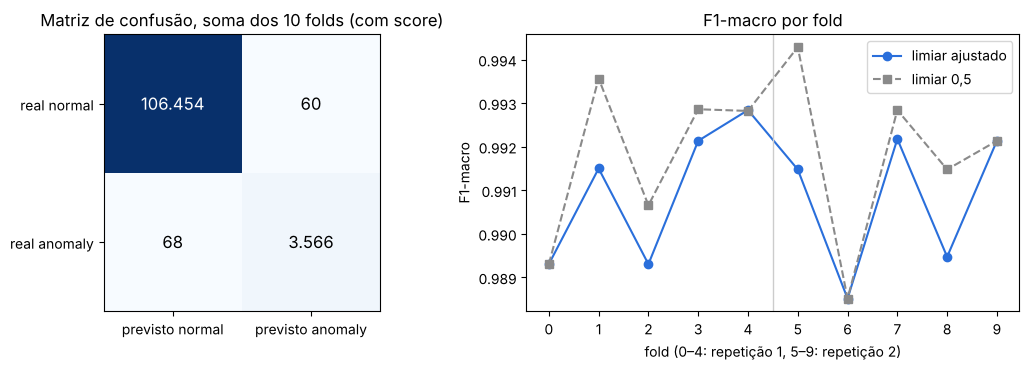

,precisão,revocação,F1,linhas reais (10 folds)
anomaly,0.9835,0.9813,0.9824,3634
normal,0.9994,0.9994,0.9994,106514


In [7]:
# [IA] Matriz de confusão somando os 10 folds e métricas por classe
mc = sum(confusion_matrix(y[iva], (probs[f] >= limiares[f]).astype(int), labels=[0, 1]) for f, (_, iva) in enumerate(FOLDS))
vn, fp, fn, vp = mc.ravel()
resumo = pd.DataFrame({
    "precisão": [vp / (vp + fp), vn / (vn + fn)],
    "revocação": [vp / (vp + fn), vn / (vn + fp)],
}, index=["anomaly", "normal"])
resumo["F1"] = 2 * resumo["precisão"] * resumo["revocação"] / (resumo["precisão"] + resumo["revocação"])
resumo["linhas reais (10 folds)"] = [vp + fn, vn + fp]
print(f"Em 10 folds: {vp} ataques pegos, {fn} ataques perdidos, {fp} alarmes falsos em {vn + fp} conexões normais "
      f"({fp / (vn + fp) * 100:.3f}%).")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].imshow(mc, cmap="Blues")
for (i, j), v in np.ndenumerate(mc):
    ax[0].text(j, i, f"{v:,}".replace(",", "."), ha="center", va="center", color="white" if v > mc.max() / 2 else "black", fontsize=12)
ax[0].set_xticks([0, 1], ["previsto normal", "previsto anomaly"]); ax[0].set_yticks([0, 1], ["real normal", "real anomaly"])
ax[0].set_title(f"Matriz de confusão, soma dos 10 folds ({VERSAO})")
ax[1].plot(por_fold.index, por_fold["F1-macro"], "o-", color=AZUL, label="limiar ajustado")
ax[1].plot(por_fold.index, por_fold["F1-macro (lim 0,5)"], "s--", color=CINZA, label="limiar 0,5")
ax[1].axvline(4.5, color="#ccc", lw=1); ax[1].set_xticks(range(10))
ax[1].set_xlabel("fold (0–4: repetição 1, 5–9: repetição 2)"); ax[1].set_ylabel("F1-macro"); ax[1].legend()
ax[1].set_title("F1-macro por fold")
plt.tight_layout(); plt.show()
resumo.round(4)

## 4. Treino final e arquivo de submissão

O modelo final é treinado nas 55.074 linhas do treino limpo, com o limiar da seção 3. Antes de gravar, o notebook confere tudo o que o enunciado exige: cabeçalho `id,class_prevista`, separador vírgula, uma linha por `id` do teste, a mesma ordem do `modelo_de_submissao.csv` e só os valores `normal` e `anomaly`, em minúsculas.

/tmp/claude-0/-home-claude/ec216b44-4777-51f5-9817-f5307ff4c81b/scratchpad/teste_pastas/Etapa 4 - Entrega final/submissao_XX.csv: 24333 linhas | limiar 0.475 | 934 anomalias previstas (3.84%) | md5 2c86135712be16f2c68b2ca9be8fc1c3
para comparar: o treino limpo tem 3.30% de anomalias e o treino bruto 5.84%

primeiras linhas do arquivo:
['id,class_prevista', '3,normal', '6,normal', '9,normal']


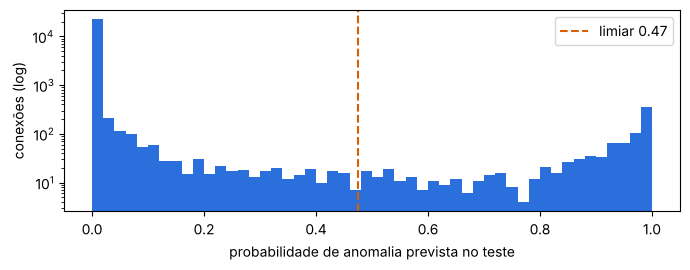

In [8]:
# [IA] Treino no treino inteiro, previsão do teste e gravação da submissão
pre_final, modelo_final = treinar(X, y)
p_teste = prever(pre_final, modelo_final, X_teste)
previsto = pd.DataFrame({"id": teste["id"].to_numpy(), "class_prevista": np.where(p_teste >= LIMIAR, "anomaly", "normal")})
sub = modelo_sub[["id"]].merge(previsto, on="id", how="left")

assert list(sub.columns) == ["id", "class_prevista"]
assert len(sub) == len(modelo_sub) == len(teste_bruto)
assert sub["id"].is_unique and (sub["id"].to_numpy() == modelo_sub["id"].to_numpy()).all()
assert sub["class_prevista"].notna().all() and set(sub["class_prevista"]) <= {"normal", "anomaly"}

arquivo = PASTA_NOTEBOOK / f"submissao_{EQUIPE}.csv"   # gravado na pasta da Etapa 4
sub.to_csv(arquivo, index=False)
assert pd.read_csv(arquivo).equals(sub)
md5 = hashlib.md5(arquivo.read_bytes()).hexdigest()
n_anom = (sub["class_prevista"] == "anomaly").sum()
print(f"{arquivo}: {len(sub)} linhas | limiar {LIMIAR:.3f} | {n_anom} anomalias previstas ({n_anom / len(sub) * 100:.2f}%) | md5 {md5}")
print(f"para comparar: o treino limpo tem {y.mean()*100:.2f}% de anomalias e o treino bruto {(treino_bruto['class'] == 'anomaly').mean()*100:.2f}%")
print("\nprimeiras linhas do arquivo:")
print(arquivo.read_text().splitlines()[:4])

plt.figure(figsize=(7, 2.8))
plt.hist(p_teste, bins=50, color=AZUL); plt.yscale("log"); plt.axvline(LIMIAR, color=LARANJA, ls="--", label=f"limiar {LIMIAR:.2f}")
plt.xlabel("probabilidade de anomalia prevista no teste"); plt.ylabel("conexões (log)"); plt.legend(); plt.tight_layout(); plt.show()

## 5. Explicabilidade

Seguimos Molnar (*Interpretable Machine Learning*, 2022), olhando o modelo de quatro jeitos diferentes, porque cada método tem um ponto cego:

1. **Importância por impureza** (a `feature_importances_` da floresta): rápida, mas favorece atributos com muitos valores distintos e é medida no treino.
2. **Importância por permutação:** embaralha um atributo de cada vez na validação do fold 0 e mede quanto o F1-macro cai. Ela mede o que o modelo **usa para acertar** em dados que não viu. Embaralhamos o atributo **original**, antes do pré-processamento, então `service` conta como um atributo só, e não como dezenas de colunas de one-hot.
3. **SHAP** (Lundberg & Lee, 2017), com o `TreeExplainer` exato para florestas: quanto cada atributo empurrou a probabilidade de **uma** conexão para cima ou para baixo.
4. **Árvore substituta** de profundidade 3, treinada para imitar as respostas da floresta: um resumo que cabe num slide, com a fidelidade medida.

Os métodos 1 a 3 usam o modelo do fold 0 da validação, porque precisam de dados com rótulo que o modelo não viu.

In [9]:
# [IA] 5.1 Importância por impureza, somando as colunas de one-hot de cada atributo
itr0, iva0 = FOLDS[0]
cols, orig = pre0.nomes()
imp = pd.Series(modelo0.feature_importances_, index=orig).groupby(level=0).sum().sort_values(ascending=False)
imp.head(15).round(4).to_frame("importância (impureza)")

,importância (impureza)
score_ids_legado,0.2081
flag,0.1205
dst_host_srv_serror_rate,0.1042
srv_serror_rate,0.0605
service,0.0604
same_srv_rate,0.0577
dst_bytes,0.0438
diff_srv_rate,0.0349
count,0.0338
dst_host_same_srv_rate,0.0331


F1-macro do fold 0 sem embaralhar: 0.9893
atributos cuja permutação não muda nada (queda ≤ 0,0005): 26 de 41


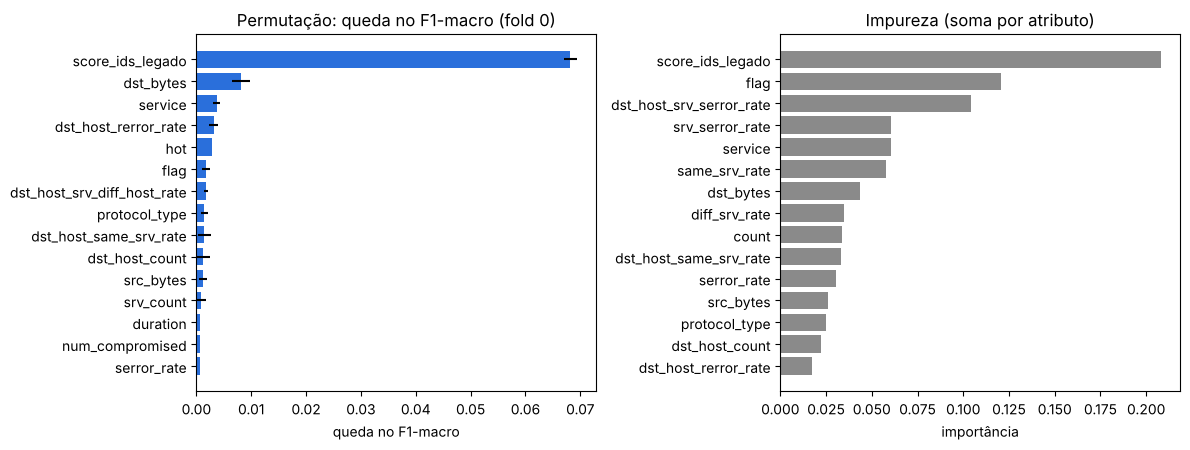

,queda no F1-macro,desvio
score_ids_legado,0.0682,0.0012
dst_bytes,0.0082,0.0016
service,0.0037,0.0006
dst_host_rerror_rate,0.0031,0.0009
hot,0.0029,0.0000
flag,0.0017,0.0007
dst_host_srv_diff_host_rate,0.0017,0.0003
protocol_type,0.0015,0.0006
dst_host_same_srv_rate,0.0014,0.0012
dst_host_count,0.0012,0.0012


In [10]:
# [IA] 5.2 Importância por permutação na validação do fold 0 (cerca de 3 min)
Xv0, yv0, lim0 = X.iloc[iva0].reset_index(drop=True), y[iva0], limiares[0]
f1_ref = f1_score(yv0, (prever(pre0, modelo0, Xv0) >= lim0).astype(int), average="macro")
rng = np.random.RandomState(SEMENTE)
atributos = [c for c in X.columns if USAR_SCORE or c != "score_ids_legado"]
quedas = {}
for c in atributos:
    q = []
    for _ in range(3):
        Xp = Xv0.copy(); Xp[c] = rng.permutation(Xp[c].to_numpy())
        q.append(f1_ref - f1_score(yv0, (prever(pre0, modelo0, Xp) >= lim0).astype(int), average="macro"))
    quedas[c] = (np.mean(q), np.std(q))
perm = pd.DataFrame(quedas, index=["queda no F1-macro", "desvio"]).T.sort_values("queda no F1-macro", ascending=False)
print(f"F1-macro do fold 0 sem embaralhar: {f1_ref:.4f}")
print(f"atributos cuja permutação não muda nada (queda ≤ 0,0005): {(perm['queda no F1-macro'] <= 0.0005).sum()} de {len(perm)}")

top = perm.head(15)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].barh(top.index, top["queda no F1-macro"], xerr=top["desvio"], color=AZUL)
ax[0].set_title("Permutação: queda no F1-macro (fold 0)"); ax[0].set_xlabel("queda no F1-macro")
ti = imp.head(15)[::-1]
ax[1].barh(ti.index, ti.values, color=CINZA); ax[1].set_title("Impureza (soma por atributo)"); ax[1].set_xlabel("importância")
plt.tight_layout(); plt.show()
perm.head(15).round(4)

SHAP em 600 conexões: 12 s | valor base (probabilidade média): 0.033


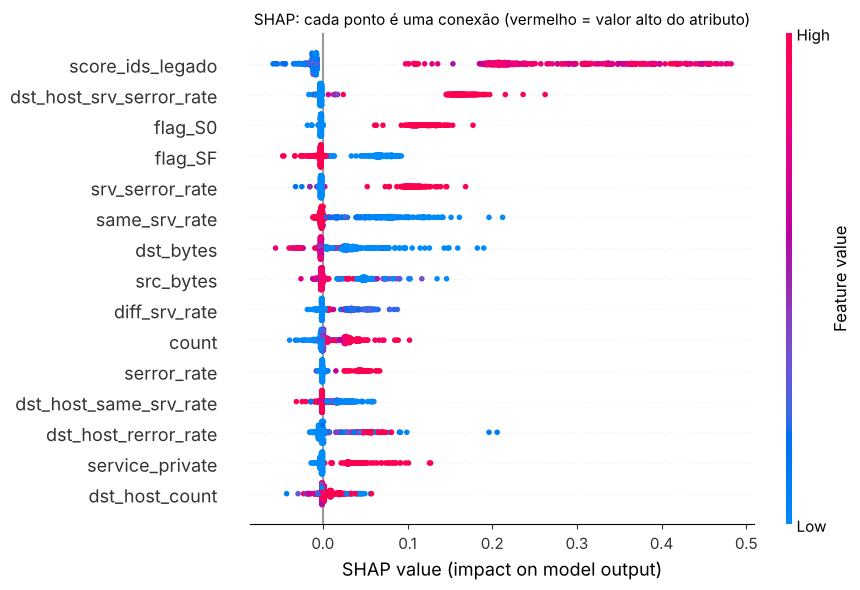

,SHAP médio |valor|,posição SHAP,posição permutação,posição impureza
score_ids_legado,0.1494,1,1,1
flag,0.0655,2,6,2
dst_host_srv_serror_rate,0.0432,3,26,3
srv_serror_rate,0.0301,4,29,4
same_srv_rate,0.0271,5,16,6
service,0.0258,6,3,5
dst_bytes,0.0219,7,2,7
src_bytes,0.0173,8,11,12
diff_srv_rate,0.0150,9,18,8
count,0.0138,10,40,9


In [11]:
# [IA] 5.3 SHAP: 300 anomalias e 300 normais da validação do fold 0
amostra = np.concatenate([rng.choice(np.where(yv0 == 1)[0], 300, replace=False),
                          rng.choice(np.where(yv0 == 0)[0], 300, replace=False)])
M = pre0.transform(Xv0.iloc[amostra])
t0 = time.time()
explicador = shap.TreeExplainer(modelo0)
sv = explicador.shap_values(M, check_additivity=False)[:, :, 1]      # contribuições para a classe anomaly
base = explicador.expected_value[1]
print(f"SHAP em {len(amostra)} conexões: {time.time() - t0:.0f} s | valor base (probabilidade média): {base:.3f}")

# soma das contribuições das colunas de one-hot de cada atributo
sv_attr = pd.DataFrame(sv, columns=orig).T.groupby(level=0).sum().T
shap_glob = sv_attr.abs().mean().sort_values(ascending=False)
comparacao = pd.DataFrame({"SHAP médio |valor|": shap_glob, "posição SHAP": range(1, len(shap_glob) + 1)})
comparacao["posição permutação"] = pd.Series(range(1, len(perm) + 1), index=perm.index).reindex(comparacao.index)
comparacao["posição impureza"] = pd.Series(range(1, len(imp) + 1), index=imp.index).reindex(comparacao.index)
shap.summary_plot(sv, M, feature_names=cols, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"SHAP: cada ponto é uma conexão (vermelho = valor alto do atributo)", fontsize=11); plt.tight_layout(); plt.show()
comparacao.head(15).round(4)

In [12]:
# [IA] 5.4 Explicações individuais: um ataque pego, um ataque perdido e um alarme falso
# os casos vêm da validação inteira do fold 0 (alarmes falsos são raros demais para aparecer na amostra do SHAP)
p_v0 = prever(pre0, modelo0, Xv0)
casos = {"ataque pego (VP)": np.where((yv0 == 1) & (p_v0 >= lim0))[0],
         "ataque perdido (FN)": np.where((yv0 == 1) & (p_v0 < lim0))[0],
         "alarme falso (FP)": np.where((yv0 == 0) & (p_v0 >= lim0))[0]}
for nome, idx in casos.items():
    if len(idx) == 0:
        print(f"{nome}: nenhum caso no fold 0\n"); continue
    # o caso mais "difícil" de cada tipo: o de probabilidade mais perto do limiar
    i = idx[np.argmin(np.abs(p_v0[idx] - lim0))]
    sv_i = explicador.shap_values(pre0.transform(Xv0.iloc[[i]]), check_additivity=False)[0, :, 1]
    contrib = pd.Series(sv_i, index=orig).groupby(level=0).sum().sort_values(key=np.abs, ascending=False).head(6)
    linha = Xv0.iloc[i]
    tab = pd.DataFrame({"valor na conexão": [linha.get(a) for a in contrib.index], "contribuição SHAP": contrib.round(3)})
    print(f"{nome} · probabilidade {p_v0[i]:.3f} (limiar {lim0:.2f}) · valor base {base:.3f} · {len(idx)} casos no fold 0")
    display(tab)

ataque pego (VP) · probabilidade 0.523 (limiar 0.48) · valor base 0.033 · 355 casos no fold 0


,valor na conexão,contribuição SHAP
score_ids_legado,0.827,0.311
src_bytes,0.0,0.135
service,ftp_data,0.036
dst_host_same_src_port_rate,1.0,0.031
dst_bytes,5636,-0.025
num_compromised,2.0,0.017


ataque perdido (FN) · probabilidade 0.477 (limiar 0.48) · valor base 0.033 · 8 casos no fold 0


,valor na conexão,contribuição SHAP
score_ids_legado,0.845,0.287
same_srv_rate,0.0,0.126
dst_bytes,1,0.078
flag,SF,-0.057
count,490.0,0.043
dst_host_diff_srv_rate,1.0,0.030


alarme falso (FP) · probabilidade 0.503 (limiar 0.48) · valor base 0.033 · 7 casos no fold 0


,valor na conexão,contribuição SHAP
score_ids_legado,0.768,0.320
service,private,0.131
dst_bytes,0,0.120
src_bytes,105.0,-0.029
flag,NaN,-0.019
logged_in,0.0,0.018


In [13]:
# [IA] 5.5 Árvore substituta: profundidade 3, imitando as respostas da floresta
# metade da validação do fold 0 treina a árvore, a outra metade mede a fidelidade
L = pre0.legivel(Xv0)
resp_rf = (p_v0 >= lim0).astype(int)
metade = np.zeros(len(L), bool); metade[rng.permutation(len(L))[: len(L) // 2]] = True
substituta = DecisionTreeClassifier(max_depth=3, random_state=SEMENTE).fit(L[metade], resp_rf[metade])
fid = (substituta.predict(L[~metade]) == resp_rf[~metade]).mean()
f1_sub = f1_score(yv0[~metade], substituta.predict(L[~metade]), average="macro")
f1_rf = f1_score(yv0[~metade], resp_rf[~metade], average="macro")
print(f"fidelidade (concorda com a floresta): {fid * 100:.2f}% | F1-macro da substituta: {f1_sub:.4f} (floresta: {f1_rf:.4f})\n")
print(export_text(substituta, feature_names=list(L.columns), class_names=["normal", "anomaly"], decimals=2))

fidelidade (concorda com a floresta): 99.18% | F1-macro da substituta: 0.9363 (floresta: 0.9891)

|--- score_ids_legado <= 0.53
|   |--- same_srv_rate <= 0.01
|   |   |--- dst_host_srv_serror_rate <= 0.35
|   |   |   |--- class: normal
|   |   |--- dst_host_srv_serror_rate >  0.35
|   |   |   |--- class: anomaly
|   |--- same_srv_rate >  0.01
|   |   |--- class: normal
|--- score_ids_legado >  0.53
|   |--- dst_bytes <= 2.50
|   |   |--- dst_host_srv_diff_host_rate <= 0.01
|   |   |   |--- class: anomaly
|   |   |--- dst_host_srv_diff_host_rate >  0.01
|   |   |   |--- class: anomaly
|   |--- dst_bytes >  2.50
|   |   |--- dst_host_rerror_rate <= 0.00
|   |   |   |--- class: normal
|   |   |--- dst_host_rerror_rate >  0.00
|   |   |   |--- class: anomaly



## 6. Onde o modelo erra

Usamos as previsões fora do fold da **repetição 1** (folds 0 a 4), em que cada linha do treino aparece exatamente uma vez na validação, cada uma com o limiar do seu fold.

In [14]:
# [IA] Erros por service, por flag, por service ausente e pelo score legado
oof = np.full(len(y), np.nan); lim_linha = np.full(len(y), np.nan)
for f in range(5):
    oof[FOLDS[f][1]] = probs[f]; lim_linha[FOLDS[f][1]] = limiares[f]
pred_oof = (oof >= lim_linha).astype(int)
E = pd.DataFrame({"service": X["service"].fillna("(ausente)"), "flag": X["flag"].fillna("(ausente)"),
                  "real": y, "previsto": pred_oof})
E["FN"] = (E.real == 1) & (E.previsto == 0); E["FP"] = (E.real == 0) & (E.previsto == 1)
print(f"repetição 1: {E.FN.sum()} ataques perdidos e {E.FP.sum()} alarmes falsos")

def tabela_erros(col, n=10):
    g = E.groupby(col).agg(linhas=("real", "size"), anomalias=("real", "sum"), FN=("FN", "sum"), FP=("FP", "sum"))
    g["erros"] = g.FN + g.FP
    g["% dos erros"] = (g.erros / g.erros.sum() * 100).round(1)
    g["revocação"] = (1 - g.FN / g.anomalias.replace(0, np.nan)).round(3)
    return g.sort_values("erros", ascending=False).head(n)

display(tabela_erros("service"))
display(tabela_erros("flag", 6))
falta = X["service"].isna()
print(f"taxa de erro com service ausente (imputado): {(E.FN | E.FP)[falta].mean()*100:.2f}% em {falta.sum()} linhas | "
      f"com service presente: {(E.FN | E.FP)[~falta].mean()*100:.2f}%")
s = X["score_ids_legado"]
faixa = pd.cut(s, [-np.inf, 0.2, 0.4, 0.6, 0.8, np.inf], labels=["< 0,2", "0,2–0,4", "0,4–0,6", "0,6–0,8", "≥ 0,8"])
faixa = faixa.cat.add_categories("(ausente)").fillna("(ausente)")
print("\nerros por faixa do score_ids_legado (mesmo quando ele não entra no modelo):")
E.assign(faixa=faixa).groupby("faixa", observed=True).agg(linhas=("real", "size"), anomalias=("real", "sum"),
                                                          FN=("FN", "sum"), FP=("FP", "sum")).assign(
    **{"% de anomalias": lambda d: (d.anomalias / d.linhas * 100).round(1)})

repetição 1: 36 ataques perdidos e 27 alarmes falsos


,linhas,anomalias,FN,FP,erros,% dos erros,revocação
service,,,,,,,
private,1762,607,5,9,14,22.2,0.992
ftp_data,3425,44,7,2,9,14.3,0.841
http,29290,108,3,4,7,11.1,0.972
eco_i,402,101,4,3,7,11.1,0.960
ftp,856,26,3,1,4,6.3,0.885
telnet,672,72,4,0,4,6.3,0.944
smtp,4934,12,3,1,4,6.3,0.750
ecr_i,212,69,0,4,4,6.3,1.000
other,1741,62,2,1,3,4.8,0.968


,linhas,anomalias,FN,FP,erros,% dos erros,revocação
flag,,,,,,,
SF,47878,363,29,20,49,77.8,0.920
(ausente),3225,117,3,2,5,7.9,0.974
S0,1127,888,3,1,4,6.3,0.997
RSTR,197,78,1,2,3,4.8,0.987
REJ,2069,305,0,2,2,3.2,1.000
OTH,6,1,0,0,0,0.0,1.000


taxa de erro com service ausente (imputado): 0.03% em 3493 linhas | com service presente: 0.12%

erros por faixa do score_ids_legado (mesmo quando ele não entra no modelo):


,linhas,anomalias,FN,FP,% de anomalias
faixa,,,,,
"< 0,2",40861,48,8,1,0.1
"0,2–0,4",10734,12,0,1,0.1
"0,4–0,6",199,45,3,0,22.6
"0,6–0,8",1070,565,14,11,52.8
"≥ 0,8",2210,1147,11,14,51.9


## 7. Discussão

**Desempenho.** Com o `score_ids_legado`, a validação dá F1-macro de **0,9909 ± 0,0016**, com o limiar entre 0,39 e 0,52 nos 10 folds (mediana 0,475). Os ataques perdidos caem de 141 para 68 e os alarmes falsos de 74 para 60, somando os 10 folds.

**O que o modelo aprendeu.** O score domina: embaralhá-lo derruba o F1-macro em 0,068, dez vezes mais do que qualquer outro atributo, e 26 dos 41 atributos passam a não fazer diferença. O que sobra de importante são os atributos que o score não cobre: `dst_bytes`, `service` e as taxas de erro de conexão. A árvore substituta mostra a divisão de trabalho: o score separa a maior parte, e os outros atributos corrigem os casos em que ele erra, como uma conexão com score alto e muitos bytes de resposta, que tende a ser normal.

**Onde o modelo erra.** O padrão continua o mesmo da versão sem score, em menor escala:
- os erros se concentram em conexões `SF` e nos serviços `private`, `ftp_data`, `http` e `smtp`;
- na faixa de score entre 0,6 e 1, em que cerca de metade das conexões é ataque, o modelo erra nos dois sentidos, e é ali que estão os casos difíceis.

### O `score_ids_legado`: usar ou não?

É o atributo mais ligado à classe (AUC de 0,968 sozinho), e o enunciado pede para investigar atributos assim antes de usá-los. Verificamos quatro coisas:

1. **Ele não "sabe" o rótulo.** Nos 1.702 grupos de linhas com os mesmos 40 atributos e classes diferentes, o `normal` e o `anomaly` têm **exatamente o mesmo score em todos os 1.702**. Se o score fosse calculado a partir da classe, como os dois atributos removidos (`tempo_resposta_analista_min` e `tipo_alerta_soc`, que só existem depois da triagem do analista), o lado `anomaly` teria score maior.
2. **Ele erra como um detector de verdade.** Entre as conexões com score ≥ 0,6, só cerca de 52% são ataques; um vazamento do rótulo seria quase perfeito.
3. **Ele traz informação que os outros atributos não têm.** Uma random forest que tenta prever o score a partir dos outros 40 atributos chega a R² = 0,30. Isso é coerente com um IDS antigo que vê coisas que a base não tem, como as assinaturas do conteúdo dos pacotes.
4. **Ele existe no teste, sem ausentes**, e se distribui de forma parecida com o treino limpo.

**Conclusão:** as evidências indicam que o score é a saída de um sistema que roda **antes** da decisão, e não um vazamento. Usá-lo é como empilhar o modelo novo sobre o IDS antigo, algo comum em um SOC. O risco é a origem dele não ser documentada; por isso o notebook tem as duas versões, e a escolha está registrada no relatório.

### Limitações

- **Menos alarmes no teste.** O modelo prevê 3,84% de anomalias no teste. Pela distribuição do score, a fração esperada de ataques fica em torno de 4,2%, então o modelo pode estar deixando passar alguns ataques.
- **Dependência do IDS legado.** O modelo fica dependente do sistema antigo: se o score mudar de calibração ou deixar de existir, o desempenho cai para o da versão sem score (0,9846).
- **Ataques novos.** Um modelo supervisionado só reconhece padrões que viu no treino (Sommer & Paxson, 2010).
- **Explicabilidade de um fold só.** A permutação e o SHAP usam o modelo do fold 0.

## 8. Checklist do enunciado

| Requisito (seção 4 do enunciado) | Onde está |
|---|---|
| 1. Tratar registros redundantes e inconsistentes | Etapa 1 (`limpeza.py`): 11.355 duplicatas e 1.702 pares contraditórios removidos; seção 1 deste notebook |
| 2. Pelo menos 2 técnicas de balanceamento | Etapa 2 (undersampling, SMOTE, `class_weight`) e Etapa 3 (oversampling aleatório na MLP; SMOTE+Tomek, SMOTE+ENN, Borderline, ADASYN e Balanced RF em testes exploratórios) |
| 3. Uma técnica de codificação, com discussão de `service` | Etapa 2 (one-hot com raras, target, frequência, ordinal); seção 2 deste notebook |
| 4. Uma técnica de normalização | Etapa 2 (`log1p` + `StandardScaler`, comparado com `RobustScaler`); Etapa 3 (Quantile e Yeo-Johnson, testes exploratórios) |
| 5. Redução de dimensionalidade ou seleção de instâncias | Etapa 2 (PCA); Etapa 3 (filtro de variância quase zero; Tomek e ENN como seleção de instâncias, em testes exploratórios) |
| 6. Pelo menos 3 algoritmos | Etapa 3: árvore de decisão, random forest e MLP com backpropagation |
| 7. Explicabilidade do melhor modelo | seção 5 deste notebook |
| Arquivo de submissão gerado pelo notebook | seção 4 deste notebook |